# Activity 6.07 — Plotting Multiple Images in a Grid

**Student:** LU MENGJIE (MC643920)  
**Purpose:** Load the four supplied images and display them in a labeled 2 × 2 grid with axes hidden.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from zipfile import ZipFile
%matplotlib inline
from pathlib import Path

def locate_datasets():
    here = Path.cwd().resolve()
    for folder in (here, *here.parents):
        candidate = folder / "Datasets"
        if candidate.is_dir():
            return candidate
    raise FileNotFoundError("Could not find the project Datasets folder.")

DATASETS = locate_datasets()
print("Datasets:", DATASETS)

Datasets: C:\Users\22392\Desktop\cisc7204_sugex06_mc643920\Submission\cisc7204_sugex06_MC643920\Datasets


In [2]:
image_files = [
    ('photo-1.jpg', 'coast'),
    ('photo-2.jpg', 'beach'),
    ('photo-3.jpg', 'building'),
    ('photo-4.jpg', 'city at night'),
]
with ZipFile(DATASETS / 'images.zip') as image_archive:
    image_archive.extractall(DATASETS)
images = [(label, mpimg.imread(DATASETS / 'images' / filename))
          for filename, label in image_files]
print('Loaded images:', [label for label, _ in images])

Loaded images: ['coast', 'beach', 'building', 'city at night']


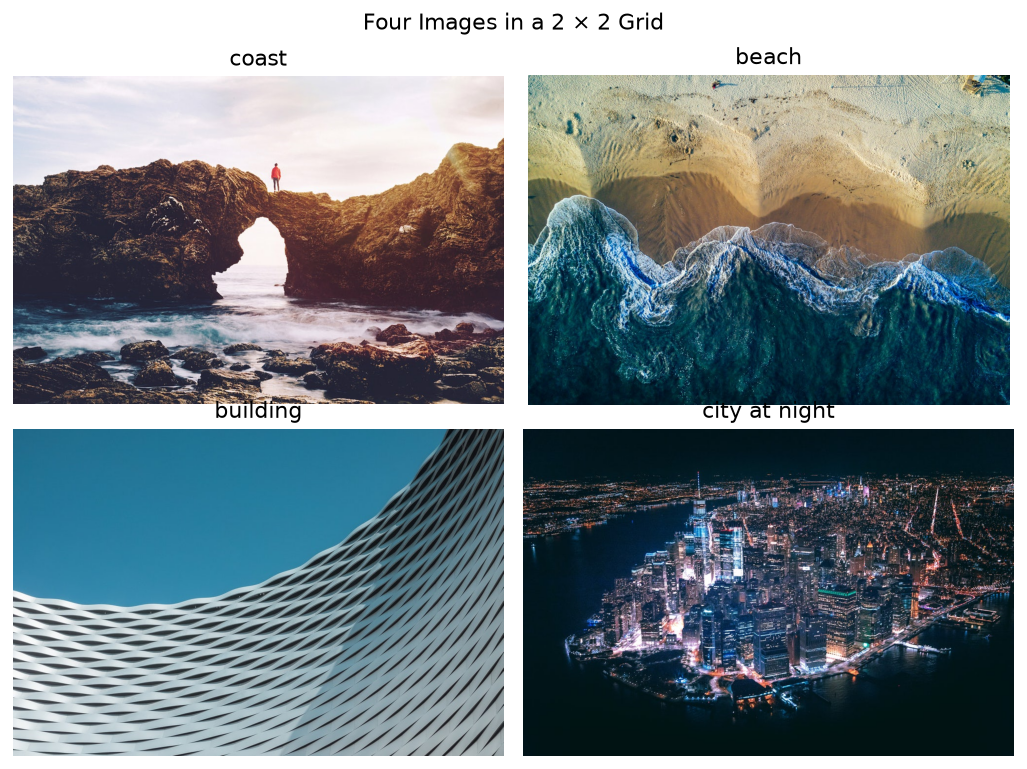

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(8, 6), dpi=130)
for ax, (label, image) in zip(axes.flat, images):
    ax.imshow(image)
    ax.set_title(label)
    ax.axis('off')
fig.suptitle('Four Images in a 2 × 2 Grid')
fig.tight_layout()
plt.show()